# Pool‑based Active Learning on a toy problem

**The question.** Notebook 1 asked *how to get more out of the labels we have*. Here we ask the question that comes first: **which points is it worth paying to label?**

**Pool‑based AL.** We have a large **pool** $\mathcal U$ of unlabelled points and an **annotator** (the oracle) who labels any point we ask for, at a cost. Starting from a tiny labelled seed $\mathcal L$, every round:

1. train the model on $\mathcal L$;
2. score every $x \in \mathcal U$ with an **acquisition function**;
3. ask the annotator to label the top‑$b$ points and move them from $\mathcal U$ to $\mathcal L$;
4. repeat until the labelling budget is spent.

- **Part A** — *naive* (random sampling) vs **uncertainty sampling with entropy**.
- **Part B** — **Deep Active Learning**: an ensemble of nets separates *aleatoric* from *epistemic* uncertainty (BALD), and we face the problem every deep AL method must solve: **batch** acquisition.

Same toy problem, same style and same two models as notebook 1.

In [1]:
import os, logging, warnings
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import FancyBboxPatch
from IPython.display import Image, Markdown, display

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.cluster import KMeans
from joblib import Parallel, delayed

warnings.filterwarnings("ignore")
os.environ["PYTHONWARNINGS"] = "ignore"                             # same for the parallel workers
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
os.makedirs("animations", exist_ok=True)

# ---- parameters -------------------------------------------------------------
NOISE      = 0.2         # noise of the moons (same as notebook 1)
POOL_SIZE  = 2000        # unlabelled pool
EASY_FRAC  = 0.8         # share of the pool made of easy, redundant points far from the boundary
N_SEED     = 20          # initial labelled seed (half per class)
BUDGET_A, BATCH_A = 100, 5      # Part A: total labels, labels per round
BUDGET_B, BATCH_B = 130, 20     # Part B: large batches
K_ENS      = 5           # ensemble size for Deep AL
RUNS_A, RUNS_B = 20, 20  # repetitions (different initial seeds)

### Visual style
All figures share one dark "neon" style: each model has its colour, class 0 is drawn in white and class 1 in the model's colour, the region the model assigns to class 1 glows in the same colour (brighter = more confident).

In [2]:
BG, PANEL, GRIDC, TXT, DIM = "#07090d", "#0e1118", "#1f2633", "#e6e9ef", "#7c8597"
MONO = ["Menlo", "DejaVu Sans Mono", "monospace"]
plt.rcParams.update({
    "font.family": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"],
    "figure.facecolor": BG, "savefig.facecolor": BG, "axes.facecolor": PANEL,
    "axes.edgecolor": GRIDC, "axes.labelcolor": DIM, "xtick.color": DIM, "ytick.color": DIM,
    "text.color": TXT, "axes.titlecolor": TXT, "legend.labelcolor": TXT, "legend.frameon": False,
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100,
})
COL = {"poly": "#4fa3ff", "nn": "#b794f4"}                          # model colours
MCOL = {"none": "#7c8597", "gmm": "#f6ad55", "mixup": "#f687b3"}    # method colours (charts)
TRUE_C = "#68d391"                                                  # the true boundary

class Panel:
    """A rounded neon card with a header (title, formula, tag), a square plot and a footer."""
    def __init__(self, fig, x, y, w, h, color, W, H, aspect=1.0):
        self.fig, self.color = fig, color
        fig.patches.append(FancyBboxPatch((x / W, y / H), w / W, h / H, transform=fig.transFigure,
                           boxstyle="round,pad=0,rounding_size=0.012", fc=PANEL, ec=color, lw=1.4, zorder=-10))
        aw = w - 0.3; ah = aw * aspect                                 # plot area follows the data aspect ratio
        if ah > h - 1.45: ah = h - 1.45; aw = ah / aspect
        self.ax = fig.add_axes([(x + (w - aw) / 2) / W, (y + 0.5 + (h - 1.45 - ah) / 2) / H, aw / W, ah / H])
        kw = dict(transform=fig.transFigure, va="center")
        self.title = fig.text((x + 0.16) / W, (y + h - 0.3) / H, "", color=color, fontsize=13, fontweight="bold", **kw)
        self.formula = fig.text((x + 0.16) / W, (y + h - 0.66) / H, "", color=TXT, fontsize=11, family=MONO, **kw)
        self.tag = fig.text((x + w - 0.16) / W, (y + h - 0.66) / H, "", color=color, fontsize=11, family=MONO, ha="right",
                            bbox=dict(boxstyle="round,pad=0.25", fc=BG, ec=color, lw=1), **kw)
        self.foot_l = fig.text((x + 0.16) / W, (y + 0.24) / H, "", color=TXT, fontsize=12, family=MONO, **kw)
        self.foot_r = fig.text((x + w - 0.16) / W, (y + 0.24) / H, "", color=DIM, fontsize=10.5, ha="right", **kw)
        if not color: self.tag.set_visible(False)

    def set(self, title=None, formula=None, tag=None, foot_l=None, foot_r=None):
        for obj, v in [(self.title, title), (self.formula, formula), (self.tag, tag), (self.foot_l, foot_l), (self.foot_r, foot_r)]:
            if v is not None: obj.set_text(v)
        self.tag.set_visible(bool(self.tag.get_text()))

def panel_grid(nrows, ncols, colors, pw=4.3, ph=None, aspect=1.0, title=None, subtitle=None, extra_right=0.0, gap=0.28):
    """Figure with nrows x ncols neon panels. colors: one colour per panel (row-major). Returns fig, panels, (W, H)."""
    top = (0.95 if subtitle else 0.7) if title else gap
    if ph is None: ph = (pw - 0.3) * aspect + 1.45
    W = ncols * pw + (ncols + 1) * gap + extra_right
    H = nrows * ph + (nrows + 1) * gap + top - gap
    fig = plt.figure(figsize=(W, H))
    if title: fig.text(0.5, 1 - 0.38 / H, title, ha="center", va="center", fontsize=18, fontweight="bold")
    if subtitle: fig.text(0.5, 1 - 0.72 / H, subtitle, ha="center", va="center", fontsize=11, color=DIM)
    panels = []
    for r in range(nrows):
        for c in range(ncols):
            x = gap + c * (pw + gap); y = H - top - (r + 1) * ph - r * gap
            panels.append(Panel(fig, x, y, pw, ph, colors[r * ncols + c], W, H, aspect))
    return fig, panels, (W, H)

def neon_chart(ax, title, xlabel="", ylabel=""):
    ax.set_facecolor(PANEL); ax.set_axisbelow(True); ax.grid(color=GRIDC, lw=0.6)
    for s in ax.spines.values(): s.set_color(GRIDC)
    ax.set_title(title, loc="left", fontsize=13, fontweight="bold", pad=10)
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)

def region_cmap(color):
    return LinearSegmentedColormap.from_list("r", [PANEL, PANEL, color], N=256)
QCOL = "#fc8181"                                                    # rings around queried points

## 1. Pool, annotator and test set

- **True function**: the same two moons as notebook 1; the **oracle** labels any point by the closest moon, and its boundary (green, dashed) is the best possible classifier.
- **Pool**: `POOL_SIZE` unlabelled points. Like a real unlabelled pool, it is **redundant**: only a small part lies on the moons, where the decision is hard; most of it (`EASY_FRAC`) is made of easy points far from the boundary, two compact blobs any model classifies correctly. In ER this is the normal situation: blocking returns a huge number of candidate pairs, and most of them are obvious non‑matches or near‑duplicates of each other.
- **Annotator**: returns the *true class* of a point — the moon it was generated from. Where the moons overlap, this can disagree with the best boundary: those points are marked ✕ (as in notebook 1). They are not mistakes of the annotator: they are **aleatoric** noise, uncertainty that no amount of labels can remove.
- **Test set**: points on the moons, labelled by the oracle — we measure how well the model solves the *hard* part of the problem (on the easy blobs every model is right anyway, so they would only dilute the differences — like true negatives in ER, which is why ER is evaluated with F1).

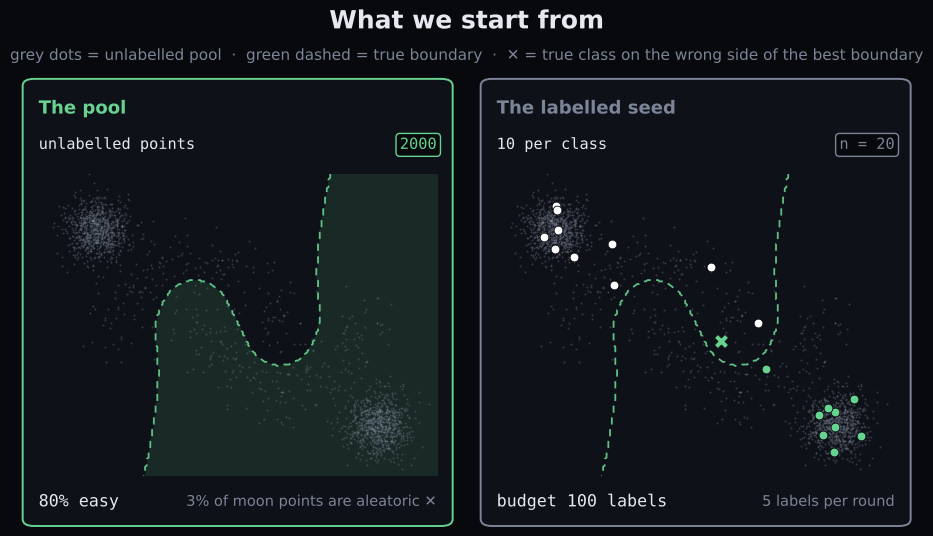

In [3]:
_t = np.linspace(0, np.pi, 1500)
ARC0, ARC1 = np.c_[np.cos(_t), np.sin(_t)], np.c_[1 - np.cos(_t), 0.5 - np.sin(_t)]

def oracle(X):
    """True label of any point: the closest moon (computed in chunks to save memory)."""
    out = []
    for i in range(0, len(X), 2000):
        x = X[i:i + 2000]
        d0 = ((x[:, None] - ARC0[None]) ** 2).sum(-1).min(1); d1 = ((x[:, None] - ARC1[None]) ** 2).sum(-1).min(1)
        out.append((d1 < d0).astype(int))
    return np.concatenate(out)

def make_moons(n, seed, noise=NOISE):
    rng = np.random.default_rng(seed)
    y = rng.integers(0, 2, n); t = rng.uniform(0, np.pi, n)
    X = np.where(y[:, None] == 0, np.c_[np.cos(t), np.sin(t)], np.c_[1 - np.cos(t), 0.5 - np.sin(t)]) + rng.normal(0, noise, (n, 2))
    return X, y

def make_easy(n, seed):
    """Easy, redundant points: two compact blobs far from the boundary, one per class."""
    rng = np.random.default_rng(seed); y = rng.integers(0, 2, n)
    return np.where(y[:, None] == 0, [-1.15, 1.35], [2.15, -0.95]) + rng.normal(0, 0.18, (n, 2)), y

N_EASY = int(EASY_FRAC * POOL_SIZE)
_Xm, _ym = make_moons(POOL_SIZE - N_EASY, seed=7); _Xe, _ye = make_easy(N_EASY, seed=8)
X_pool, y_pool = np.vstack([_Xm, _Xe]), np.r_[_ym, _ye]   # y_pool is hidden: it is what the annotator answers
IS_EASY = np.r_[np.zeros(len(_Xm), bool), np.ones(N_EASY, bool)]
X_te, _ = make_moons(3000, seed=999); y_te = oracle(X_te)

def annotate(idx):
    """The annotator: true class of the requested pool points."""
    return y_pool[idx]

def initial_seed(seed):
    rng = np.random.default_rng(seed)
    return list(np.r_[rng.choice(np.where(y_pool == 0)[0], N_SEED // 2, replace=False),
                      rng.choice(np.where(y_pool == 1)[0], N_SEED // 2, replace=False)])

XL, YL = (-1.85, 2.85), (-1.55, 2.0)
_gx, _gy = np.meshgrid(np.linspace(*XL, 230), np.linspace(*YL, 230))
GRID = np.c_[_gx.ravel(), _gy.ravel()]
TRUE_Z = oracle(GRID).reshape(_gx.shape)
ASP = (YL[1] - YL[0]) / (XL[1] - XL[0])

def draw_points(ax, X, y, color, s=30):
    wrong = oracle(X) != y
    ax.scatter(*X[(y == 0) & ~wrong].T, s=s, c="white", edgecolors=BG, linewidths=0.6, zorder=4)
    ax.scatter(*X[(y == 1) & ~wrong].T, s=s, c=color, edgecolors=BG, linewidths=0.6, zorder=4)
    ax.scatter(*X[(y == 0) & wrong].T, s=s * 2.6, c="white", marker="X", edgecolors=BG, linewidths=0.6, zorder=5)
    ax.scatter(*X[(y == 1) & wrong].T, s=s * 2.6, c=color, marker="X", edgecolors=BG, linewidths=0.6, zorder=5)

def draw_true(ax):
    ax.contour(_gx, _gy, TRUE_Z, levels=[0.5], colors=[TRUE_C], linewidths=1.3, linestyles=[(0, (4, 3))], alpha=0.9)

def draw_model(ax, model, color, X=None, y=None, X_aug=None, y_aug=None, show_true=True):
    p = model.predict_proba(GRID)[:, 1].reshape(_gx.shape)
    ax.imshow(p, extent=(*XL, *YL), origin="lower", cmap=region_cmap(color), vmin=0, vmax=1, alpha=0.6, interpolation="bilinear", aspect="auto")
    for lw, a in [(7, 0.08), (4, 0.18), (1.6, 1.0)]:                   # glowing boundary
        ax.contour(_gx, _gy, p, levels=[0.5], colors=[color], linewidths=lw, alpha=a)
    if show_true: draw_true(ax)
    if X_aug is not None:
        ax.scatter(*X_aug[y_aug == 0].T, s=6, c="white", alpha=0.35, lw=0, zorder=2)
        ax.scatter(*X_aug[y_aug == 1].T, s=6, c=color, alpha=0.5, lw=0, zorder=2)
    if X is not None: draw_points(ax, X, y, color)
    clean(ax)

def clean(ax):
    ax.set(xlim=XL, ylim=YL, xticks=[], yticks=[], aspect="equal")
    for s in ax.spines.values(): s.set_visible(False)


def draw_pool(ax):
    ax.scatter(*X_pool.T, s=2, c=DIM, alpha=0.35, lw=0, zorder=1)

def draw_queries(ax, X, color=QCOL):
    for s_, a in [(260, 0.15), (120, 1.0)]:
        ax.scatter(*X.T, s=s_, facecolors="none", edgecolors=color, linewidths=1.8 if a == 1 else 5, alpha=a, zorder=6)

L0 = initial_seed(0)
fig, P, _ = panel_grid(1, 2, [TRUE_C, DIM], aspect=ASP, title="What we start from",
                       subtitle="grey dots = unlabelled pool  ·  green dashed = true boundary  ·  ✕ = true class on the wrong side of the best boundary")
ax = P[0].ax; ax.imshow(TRUE_Z, extent=(*XL, *YL), origin="lower", cmap=region_cmap(TRUE_C), vmin=0, vmax=1.6, alpha=0.5, aspect="auto")
draw_true(ax); draw_pool(ax); clean(ax)
wrong = (oracle(X_pool) != y_pool).mean()
P[0].set(title="The pool", formula="unlabelled points", tag=f"{POOL_SIZE}", foot_l=f"{EASY_FRAC:.0%} easy", foot_r=f"{(oracle(_Xm) != _ym).mean():.0%} of moon points are aleatoric ✕")
ax = P[1].ax; ax.set_facecolor(PANEL); draw_true(ax); draw_pool(ax); draw_points(ax, X_pool[L0], y_pool[L0], TRUE_C, s=40); clean(ax)
P[1].set(title="The labelled seed", formula=f"{N_SEED // 2} per class", tag=f"n = {N_SEED}", foot_l=f"budget {BUDGET_A} labels", foot_r=f"{BATCH_A} labels per round")
plt.show()

## 2. Models and the AL loop

Same two models as notebook 1. The net is retrained from scratch at every round, so we cap it at 1000 epochs (instead of 3000) to keep the loop fast.

A **strategy** is a function `query(L, U, b, rng, seed) -> (indices to label, fitted model)`. The loop is shared by all strategies, so the comparison is fair: same seed set, same model, same budget.

**Curves.** Each curve is the mean over several runs (different initial seeds). The shaded band is the **95 % confidence interval of the mean**: how precisely we know the average curve. Single runs vary much more than this — mostly because of *which* points end up labelled, not because of the training noise of the net.

In [4]:
def poly_model(seed=0):
    return make_pipeline(PolynomialFeatures(degree=9), StandardScaler(), LogisticRegression(C=1e4, max_iter=20000))

def nn_model(seed=0):
    return MLPClassifier(hidden_layer_sizes=(32, 32), alpha=1e-5, max_iter=1000, tol=1e-6, random_state=seed)

MODELS = {"poly": dict(name="Polynomial", formula="p = σ(w·φ₉(x) + b)", make=poly_model),
          "nn":   dict(name="Neural net", formula="2 layers × 32, ReLU", make=nn_model)}

def entropy(p):
    return -(p * np.log(p + 1e-12)).sum(axis=1)

class Ensemble:
    """K nets trained from different random initialisations; predicts the average."""
    def __init__(self, nets): self.nets = nets
    def predict_proba(self, X): return np.mean([n.predict_proba(X) for n in self.nets], axis=0)
    def score(self, X, y): return (self.predict_proba(X).argmax(1) == y).mean()

def active_learning(query, seed, b, budget, keep_history=False):
    warnings.filterwarnings("ignore")
    rng = np.random.default_rng(seed); L = initial_seed(seed)
    curve, history = [], []
    while True:
        U = np.setdiff1d(np.arange(POOL_SIZE), L)
        new, model = query(L, U, b, rng, seed)            # train on L, pick b points from U
        curve.append((len(L), model.score(X_te, y_te)))
        if keep_history: history.append((list(L), new, model))
        if len(L) >= budget: break
        annotate(new)                                     # the annotator labels them
        L = L + list(new)
    return np.array(curve), history

def run_strategy(query, b, budget, runs):
    curves = Parallel(n_jobs=-1)(delayed(active_learning)(query, s, b, budget) for s in range(runs))
    return curves[0][0][:, 0], np.array([c[0][:, 1] for c in curves])

def plot_curves(ax, results, colors, title, styles=None):
    """Mean curve over runs; band = 95% confidence interval of the mean (1.96 · std / √runs)."""
    neon_chart(ax, title, "number of labelled points", "test accuracy")
    for name, (n, acc) in results.items():
        mu = acc.mean(0); ci = 1.96 * acc.std(0, ddof=1) / np.sqrt(len(acc)); ls = (styles or {}).get(name, "-")
        ax.plot(n, mu, color=colors[name], lw=2.4 if ls == "-" else 1.6, ls=ls, label=name)
        ax.fill_between(n, mu - ci, mu + ci, color=colors[name], alpha=0.12)
    ax.legend(loc="lower right", fontsize=9)

# Part A — Naive vs entropy

- **Random (naive / passive)**: pick $b$ points uniformly from $\mathcal U$ — what we do when we just "label some more data".
- **Entropy (uncertainty sampling)**: pick the points where the current model is least sure,
$$x^* = \arg\max_{x\in\mathcal U} H[y\mid x] = -\sum_c p(c\mid x)\log p(c\mid x).$$
In binary classification this means the points closest to the decision boundary ($p\approx 0.5$).

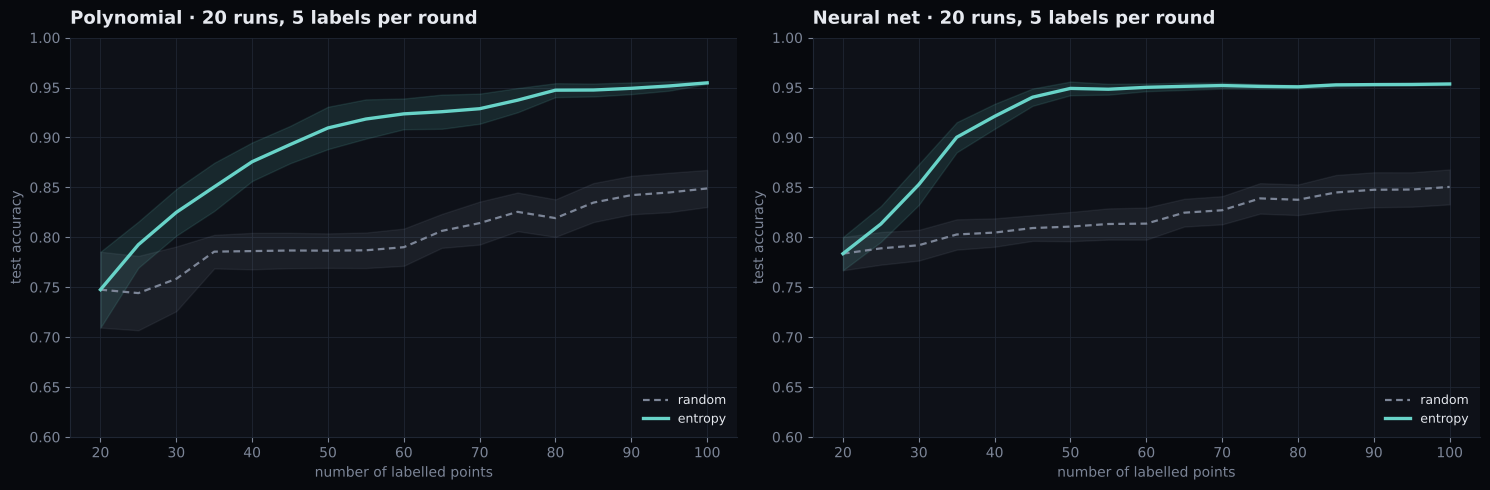

             strategy     @30     @50    @100   labels to reach 95%
Polynomial   random     0.758   0.787   0.849   None
Polynomial   entropy    0.825   0.910   0.955   95
Neural net   random     0.792   0.811   0.850   None
Neural net   entropy    0.853   0.949   0.954   60


In [5]:
def make_queries(model_key):
    make = MODELS[model_key]["make"]
    def q_random(L, U, b, rng, seed):
        return rng.choice(U, b, replace=False), make(seed).fit(X_pool[L], y_pool[L])
    def q_entropy(L, U, b, rng, seed):
        m = make(seed).fit(X_pool[L], y_pool[L])
        return U[np.argsort(-entropy(m.predict_proba(X_pool[U])))[:b]], m
    return q_random, q_entropy

RES_A = {}
for mk in MODELS:
    q_random, q_entropy = make_queries(mk)
    RES_A[(mk, "random")] = run_strategy(q_random, BATCH_A, BUDGET_A, RUNS_A)
    RES_A[(mk, "entropy")] = run_strategy(q_entropy, BATCH_A, BUDGET_A, RUNS_A)

SCOL = {"random": MCOL["none"], "entropy": "#68d3c8", "bald": "#f6ad55", "entropy + diversity": "#f687b3", "BALD + diversity": "#fbd38d"}
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, mk in zip(axes, MODELS):
    res = {"random": RES_A[(mk, "random")], "entropy": RES_A[(mk, "entropy")]}
    plot_curves(ax, res, SCOL, f"{MODELS[mk]['name']} · {RUNS_A} runs, {BATCH_A} labels per round", styles={"random": (0, (3, 2))})
    ax.set_ylim(0.6, 1.0); ax.title.set_color(COL[mk])
plt.tight_layout(); plt.show()

def labels_to_reach(n, acc, target):
    mu = acc.mean(0); return int(n[np.argmax(mu >= target)]) if (mu >= target).any() else None

print(f"{'':12s} {'strategy':8s} {'@30':>7s} {'@50':>7s} {'@' + str(BUDGET_A):>7s}   labels to reach 95%")
for mk in MODELS:
    for st in ("random", "entropy"):
        n, acc = RES_A[(mk, st)]; mu = acc.mean(0)
        print(f"{MODELS[mk]['name']:12s} {st:8s} {mu[n == 30][0]:7.3f} {mu[n == 50][0]:7.3f} {mu[-1]:7.3f}   {labels_to_reach(n, acc, 0.95)}")

The gap is large for **both models**: with random sampling most labels land on the easy blobs and accuracy creeps up slowly; with entropy every label goes where the model is unsure, and the net reaches 95 % with a fraction of the budget — random sampling does not get there at all within the budget.

The polynomial needs more labels than the net to get there: its uncertainty is less reliable (see below).

### Where do the two strategies spend their labels?
One representative run (the one closest to the average curves), neural net. Rings = points queried in that round.

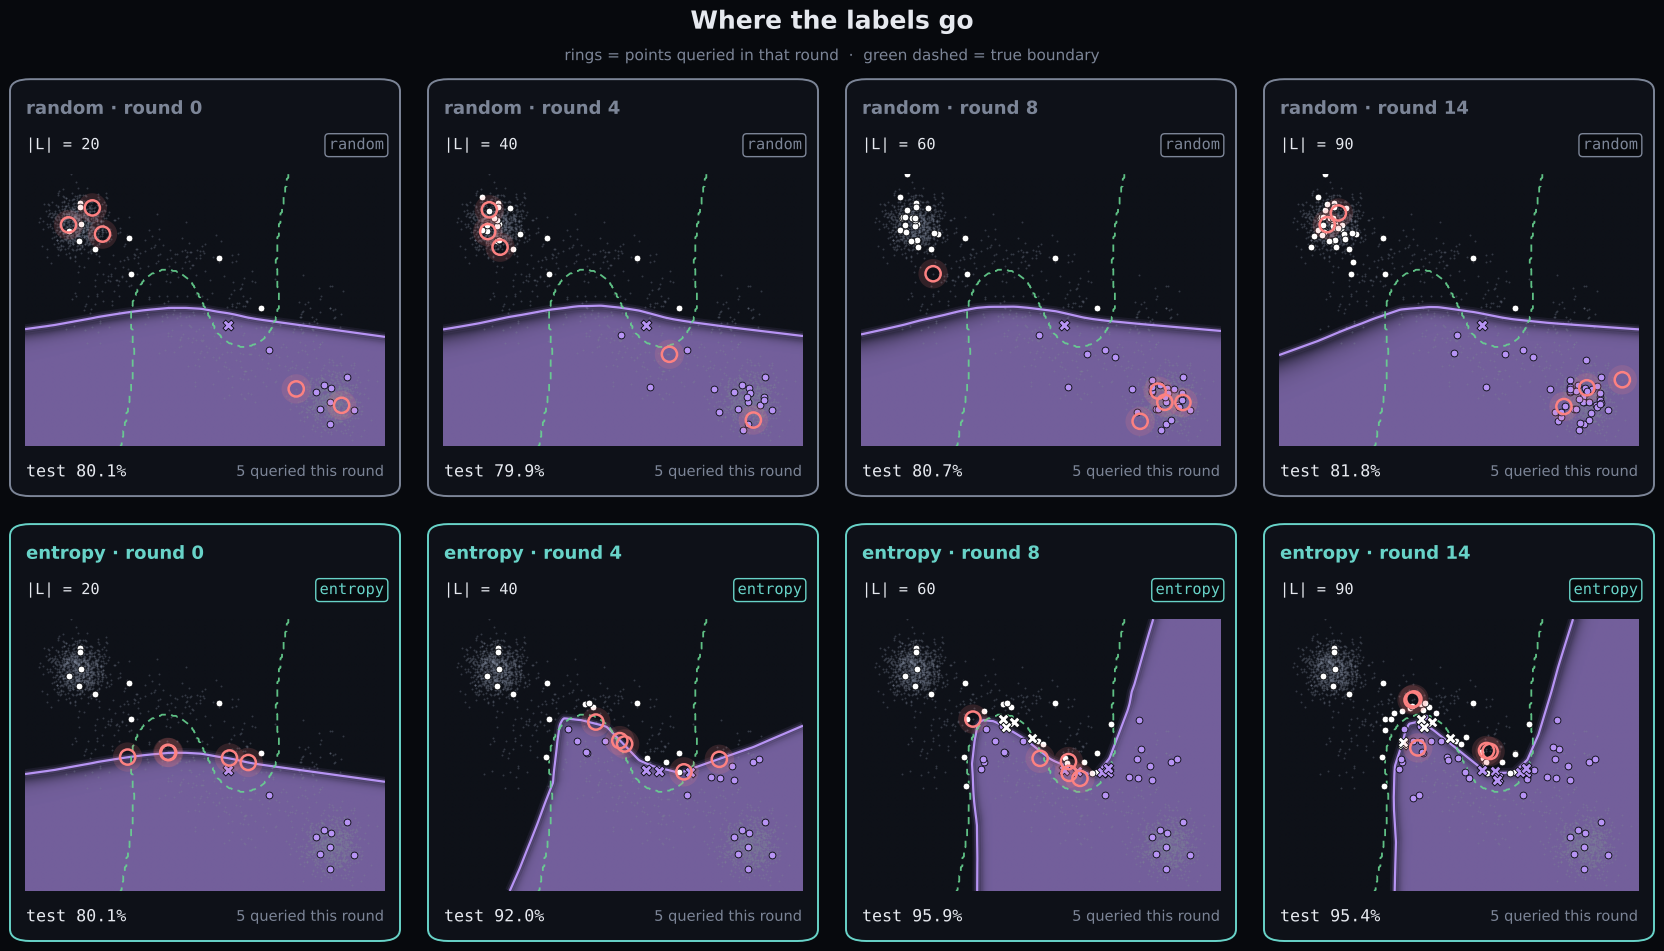

In [6]:
nn_rand, nn_ent = make_queries("nn")
mean_r, mean_e = RES_A[("nn", "random")][1].mean(0), RES_A[("nn", "entropy")][1].mean(0)
REP = int(np.argmin([((RES_A[("nn", "random")][1][s] - mean_r) ** 2).sum() + ((RES_A[("nn", "entropy")][1][s] - mean_e) ** 2).sum() for s in range(RUNS_A)]))
HIST = {"random": active_learning(nn_rand, REP, BATCH_A, BUDGET_A, keep_history=True)[1],
        "entropy": active_learning(nn_ent, REP, BATCH_A, BUDGET_A, keep_history=True)[1]}

def plot_state(p_, model, L, new, color, title, tag):
    ax = p_.ax; ax.clear(); ax.set_facecolor(PANEL)
    pr = model.predict_proba(GRID)[:, 1].reshape(_gx.shape)
    ax.imshow(pr, extent=(*XL, *YL), origin="lower", cmap=region_cmap(color), vmin=0, vmax=1, alpha=0.6, interpolation="bilinear", aspect="auto")
    for lw, a in [(7, 0.08), (4, 0.18), (1.6, 1.0)]:
        ax.contour(_gx, _gy, pr, levels=[0.5], colors=[color], linewidths=lw, alpha=a)
    draw_true(ax); draw_pool(ax); draw_points(ax, X_pool[L], y_pool[L], color, s=24)
    if new is not None and len(new): draw_queries(ax, X_pool[new])
    clean(ax)
    p_.set(title=title, formula=f"|L| = {len(L)}", tag=tag, foot_l=f"test {model.score(X_te, y_te):.1%}", foot_r=f"{len(new) if new is not None else 0} queried this round")

ROUNDS = [0, 4, 8, 14]
fig, P, _ = panel_grid(2, 4, [SCOL["random"]] * 4 + [SCOL["entropy"]] * 4, pw=3.9, aspect=ASP, title="Where the labels go",
                       subtitle="rings = points queried in that round  ·  green dashed = true boundary")
for r, st in enumerate(["random", "entropy"]):
    for c, rd in enumerate(ROUNDS):
        L, new, m = HIST[st][rd]; plot_state(P[r * 4 + c], m, L, new, COL["nn"], f"{st} · round {rd}", st)
plt.show()

Random sampling follows the pool: about 80 % of its labels land on the **easy blobs**, where the model is already right, and the boundary on the moons barely moves. Entropy ignores the blobs and spends its labels **along the current boundary**: each new label corrects the boundary exactly where it is unsure.

Notice also that entropy keeps querying the **overlap of the two moons**, where the answers are often ✕: the model is uncertain there *because the labels really are ambiguous*, and new labels cannot fix that. Part B separates this kind of uncertainty from the useful one.

### Animation: round by round
Output: `animations/al_rounds.mp4` (for slides) and `animations/al_rounds.gif`.

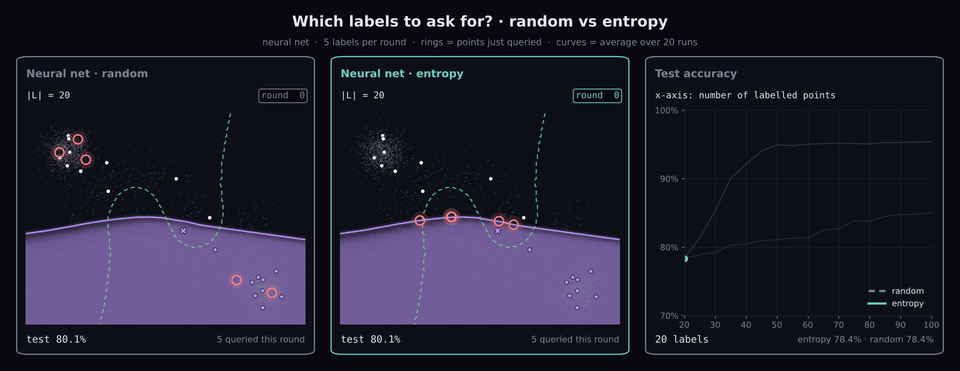

In [7]:
fig, P, (W, H) = panel_grid(1, 3, [SCOL["random"], SCOL["entropy"], DIM], pw=5.0, aspect=ASP,
                            title="Which labels to ask for? · random vs entropy",
                            subtitle=f"neural net  ·  {BATCH_A} labels per round  ·  rings = points just queried  ·  curves = average over {RUNS_A} runs")
cax = P[2].ax; pos = cax.get_position()
cax.set_position([pos.x0 + 0.5 / W, pos.y0 + 0.15 / H, pos.width - 0.55 / W, pos.height - 0.1 / H])
neon_chart(cax, ""); cax.set_title(""); cax.set_xlim(N_SEED, BUDGET_A); cax.set_ylim(0.7, 1.0)
cax.set_yticks([0.7, 0.8, 0.9, 1.0]); cax.set_yticklabels(["70%", "80%", "90%", "100%"])
P[2].set(title="Test accuracy", formula="x-axis: number of labelled points", tag="")
n_axis = RES_A[("nn", "random")][0]
for st in ("random", "entropy"):
    mu = RES_A[("nn", st)][1].mean(0); cax.plot(n_axis, mu, color=SCOL[st], lw=1, alpha=0.25)
LINES = {st: cax.plot([], [], color=SCOL[st], lw=2.6, ls="-" if st == "entropy" else (0, (3, 2)), label=st)[0] for st in ("random", "entropy")}
DOTS = {st: cax.plot([], [], "o", color=SCOL[st], ms=7)[0] for st in ("random", "entropy")}
cax.legend(loc="lower right", fontsize=10)

def draw_round(rd):
    for p_, st in zip(P[:2], ["random", "entropy"]):
        L, new, m = HIST[st][rd]; plot_state(p_, m, L, new, COL["nn"], f"Neural net · {st}", f"round {rd:>2d}")
        mu = RES_A[("nn", st)][1].mean(0)[: rd + 1]; LINES[st].set_data(n_axis[: rd + 1], mu); DOTS[st].set_data([n_axis[rd]], [mu[-1]])
    P[2].set(foot_l=f"{int(n_axis[rd])} labels", foot_r=f"entropy {RES_A[('nn', 'entropy')][1].mean(0)[rd]:.1%} · random {RES_A[('nn', 'random')][1].mean(0)[rd]:.1%}")
    return []

n_rounds = len(HIST["random"])
anim = animation.FuncAnimation(fig, draw_round, frames=list(range(n_rounds)) + [n_rounds - 1] * 6, blit=False)
if animation.writers.is_available("ffmpeg"):
    fig.set_dpi(1920 / W)
    anim.save("animations/al_rounds.mp4", writer=animation.FFMpegWriter(fps=3, bitrate=6000,
              extra_args=["-vf", "scale=trunc(iw/2)*2:trunc(ih/2)*2", "-pix_fmt", "yuv420p"]))
    os.system('ffmpeg -loglevel error -y -i animations/al_rounds.mp4 -vf "fps=3,scale=960:-1:flags=lanczos,split[a][b];'
              '[a]palettegen[p];[b][p]paletteuse" animations/al_rounds.gif')
else:
    fig.set_dpi(960 / W)
    anim.save("animations/al_rounds.gif", writer=animation.PillowWriter(fps=3))
plt.close(fig)
display(Image(filename="animations/al_rounds.gif"))

### The acquisition function inherits the model's uncertainty
Same labelled points (the entropy run above, round 8): what each model believes it does not know. Bright = high entropy = where entropy sampling would query next.

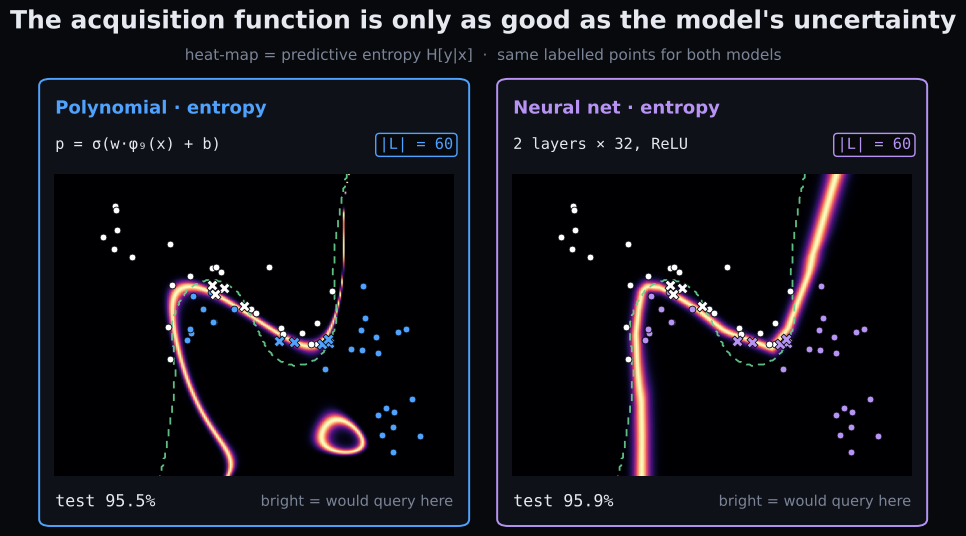

In [8]:
L8 = HIST["entropy"][8][0]
fig, P, _ = panel_grid(1, 2, [COL["poly"], COL["nn"]], aspect=ASP, title="The acquisition function is only as good as the model's uncertainty",
                       subtitle="heat-map = predictive entropy H[y|x]  ·  same labelled points for both models")
for p_, mk in zip(P, MODELS):
    m = MODELS[mk]["make"]().fit(X_pool[L8], y_pool[L8]); ax = p_.ax; ax.set_facecolor(PANEL)
    ax.imshow(entropy(m.predict_proba(GRID)).reshape(_gx.shape), extent=(*XL, *YL), origin="lower", cmap="magma", vmin=0, vmax=np.log(2), aspect="auto")
    draw_true(ax); draw_points(ax, X_pool[L8], y_pool[L8], COL[mk], s=24); clean(ax)
    p_.set(title=f"{MODELS[mk]['name']} · entropy", formula=MODELS[mk]["formula"], tag=f"|L| = {len(L8)}",
           foot_l=f"test {m.score(X_te, y_te):.1%}", foot_r="bright = would query here")
plt.show()

Both models are unsure along the moons, but the polynomial is also "unsure" in places that say nothing about the true boundary — closed rings and bands in empty regions, artefacts of a degree‑9 polynomial. Queries spent there are wasted, which is why it needs more labels. Uncertainty sampling inherits every flaw of the model's confidence — the motivation for the better uncertainty estimates of Part B.

# Part B — Deep Active Learning

Two things change when the learner is a deep network:

1. **Uncertainty.** A single network's softmax is often over‑confident and mixes two kinds of uncertainty:
   - *aleatoric*: the label itself is ambiguous (here: where the moons overlap) — more labels will **not** help;
   - *epistemic*: the model has not seen enough data there — **this is what labels fix**.

   We approximate a Bayesian posterior over the weights with a **deep ensemble** of $K$ nets trained from different random initialisations (MC‑Dropout is the other common choice, not available in scikit‑learn). Then
   $$\underbrace{H\big[\tfrac1K\textstyle\sum_k p_k(y\mid x)\big]}_{\text{total}} \;=\; \underbrace{\tfrac1K\textstyle\sum_k H[p_k(y\mid x)]}_{\text{aleatoric}} \;+\; \underbrace{I[y;\theta\mid x]}_{\text{epistemic = BALD}}$$
   **BALD** (Houlsby et al. 2011; Gal et al. 2017) queries the points where the ensemble members **disagree**.

2. **Batches.** Retraining a deep model after every label is too expensive, so deep AL queries **large batches**. Taking the top‑$b$ scores then picks $b$ near‑duplicates from the same uncertain spot; deep AL methods (Core‑Set, BADGE, BatchBALD, …) all add some form of **diversity**.

In [9]:
def fit_ensemble(L, seed):
    return Ensemble([nn_model(seed * 100 + k).fit(X_pool[L], y_pool[L]) for k in range(K_ENS)])

def decompose(ens, X):
    P_ = np.stack([n.predict_proba(X) for n in ens.nets])
    total = entropy(P_.mean(0)); aleatoric = np.mean([entropy(p) for p in P_], axis=0)
    return total, aleatoric, total - aleatoric

### What the ensemble sees
Same labelled points (entropy run, round 8). Three uncertainty maps from the same ensemble.

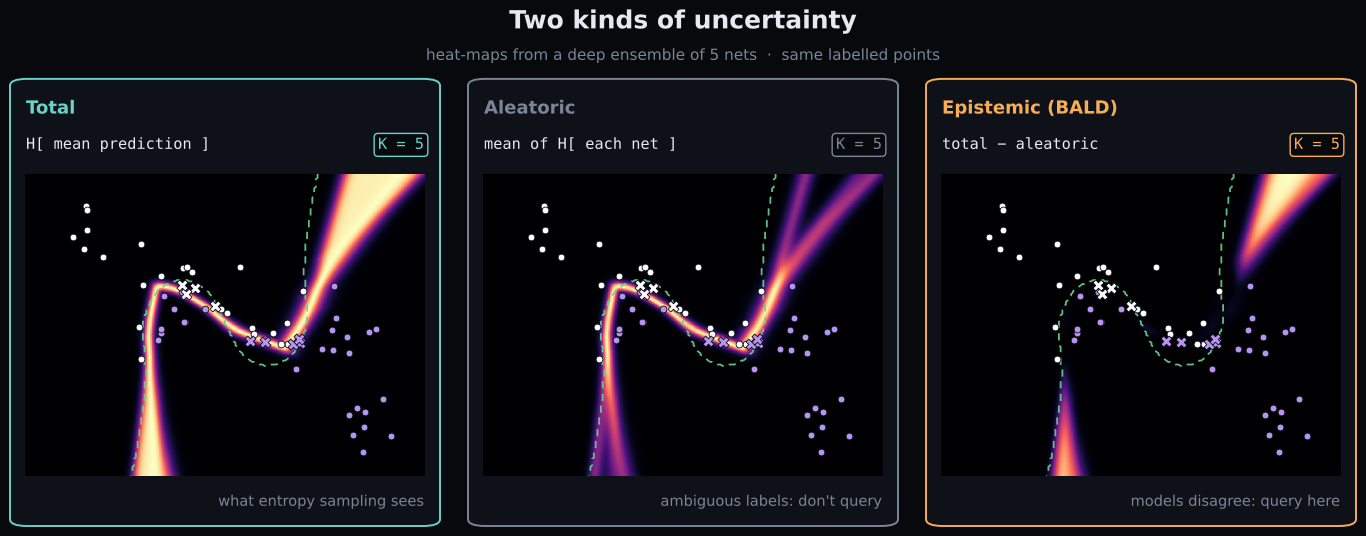

In [10]:
ens = fit_ensemble(L8, 0)
tot, ale, epi = [u.reshape(_gx.shape) for u in decompose(ens, GRID)]
fig, P, _ = panel_grid(1, 3, [SCOL["entropy"], DIM, SCOL["bald"]], aspect=ASP, title="Two kinds of uncertainty",
                       subtitle="heat-maps from a deep ensemble of 5 nets  ·  same labelled points")
for p_, (Z, ttl, frm, foot) in zip(P, [(tot, "Total", "H[ mean prediction ]", "what entropy sampling sees"),
                                      (ale, "Aleatoric", "mean of H[ each net ]", "ambiguous labels: don't query"),
                                      (epi, "Epistemic (BALD)", "total − aleatoric", "models disagree: query here")]):
    ax = p_.ax; ax.set_facecolor(PANEL)
    ax.imshow(Z, extent=(*XL, *YL), origin="lower", cmap="magma", vmin=0, vmax=max(Z.max(), 1e-3), aspect="auto")
    draw_true(ax); draw_points(ax, X_pool[L8], y_pool[L8], COL["nn"], s=24); clean(ax)
    p_.set(title=ttl, formula=frm, tag=f"K = {K_ENS}", foot_l="", foot_r=foot)
plt.show()

The **aleatoric** map lights up along the boundary, where the moons overlap and the labels are genuinely mixed. The **epistemic** map lights up where the nets *disagree*: far from the labelled points, where different plausible boundaries are possible — that is where BALD spends labels. (Pool‑based AL only scores pool points, so the empty corners of the plane are never queried.)

Caveat: with few labels and only 5 nets the decomposition is an approximation — each net's own sharp boundary also shows up as "aleatoric".

### Deep AL strategies with large batches

Now $b$ = `BATCH_B` labels per round:

| strategy | uncertainty | batch selection |
|---|---|---|
| random | – | random |
| entropy (top‑$b$) | single net, total | top‑$b$ |
| BALD (top‑$b$) | ensemble, epistemic | top‑$b$ |
| entropy + diversity | single net, total | cluster the top‑$10b$ with k‑means, take the best of each cluster |
| **BALD + diversity** | ensemble, epistemic | cluster the top‑$10b$ with k‑means, take the best of each cluster |

The "+ diversity" rule is a simple version of what Core‑Set / BADGE do: restrict to informative candidates, then spread the batch so that no two queries are redundant.

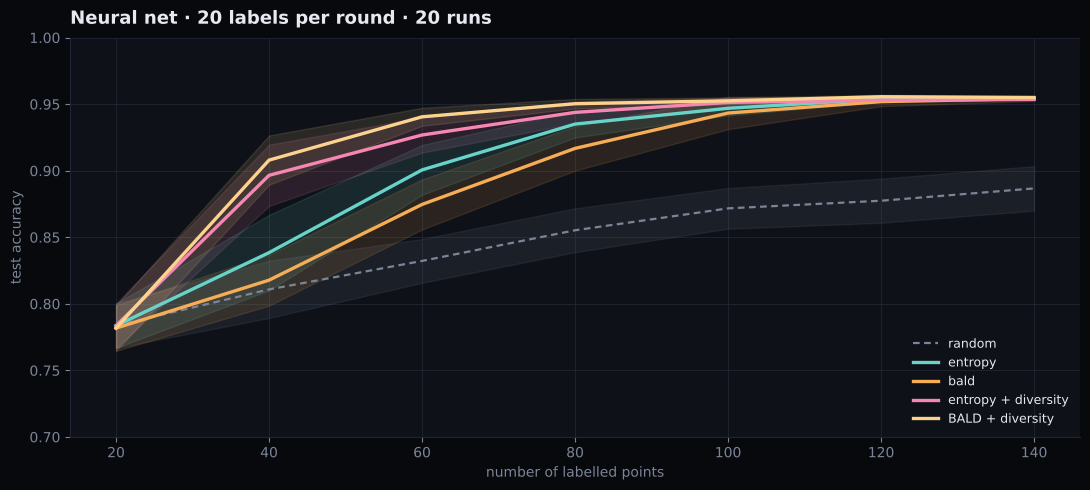

strategy                   @20     @40     @60     @80    @100    @120    @140
random                   0.784   0.811   0.832   0.855   0.872   0.877   0.887
entropy                  0.784   0.838   0.901   0.935   0.947   0.954   0.954
bald                     0.782   0.818   0.875   0.917   0.943   0.952   0.954
entropy + diversity      0.784   0.897   0.927   0.944   0.951   0.953   0.954
BALD + diversity         0.782   0.908   0.940   0.950   0.953   0.956   0.955


In [11]:
def diverse_topk(U, scores, b, seed, factor=10):
    top = np.argsort(-scores)[: factor * b]
    km = KMeans(n_clusters=b, n_init=3, random_state=seed).fit(X_pool[U[top]])
    return U[np.array([top[km.labels_ == c][np.argmax(scores[top][km.labels_ == c])] for c in range(b)])]

def q_bald(L, U, b, rng, seed):
    e = fit_ensemble(L, seed); return U[np.argsort(-decompose(e, X_pool[U])[2])[:b]], e

def q_entropy_div(L, U, b, rng, seed):
    m = nn_model(seed).fit(X_pool[L], y_pool[L]); return diverse_topk(U, entropy(m.predict_proba(X_pool[U])), b, seed), m

def q_bald_div(L, U, b, rng, seed):
    e = fit_ensemble(L, seed); return diverse_topk(U, decompose(e, X_pool[U])[2], b, seed), e

B_STRATS = {"random": nn_rand, "entropy": nn_ent, "bald": q_bald, "entropy + diversity": q_entropy_div, "BALD + diversity": q_bald_div}
RES_B = {name: run_strategy(q, BATCH_B, BUDGET_B, RUNS_B) for name, q in B_STRATS.items()}

fig, ax = plt.subplots(figsize=(11, 5))
plot_curves(ax, RES_B, SCOL, f"Neural net · {BATCH_B} labels per round · {RUNS_B} runs", styles={"random": (0, (3, 2))})
ax.set_ylim(0.7, 1.0); plt.tight_layout(); plt.show()

n_b = RES_B["random"][0]
print(f"{'strategy':22s} " + " ".join(f"{'@' + str(int(n)):>7s}" for n in n_b))
for name, (n, acc) in RES_B.items():
    print(f"{name:22s} " + " ".join(f"{v:7.3f}" for v in acc.mean(0)))

### Why top‑$b$ breaks with large batches
The first batch of each strategy (same 10 starting labels).

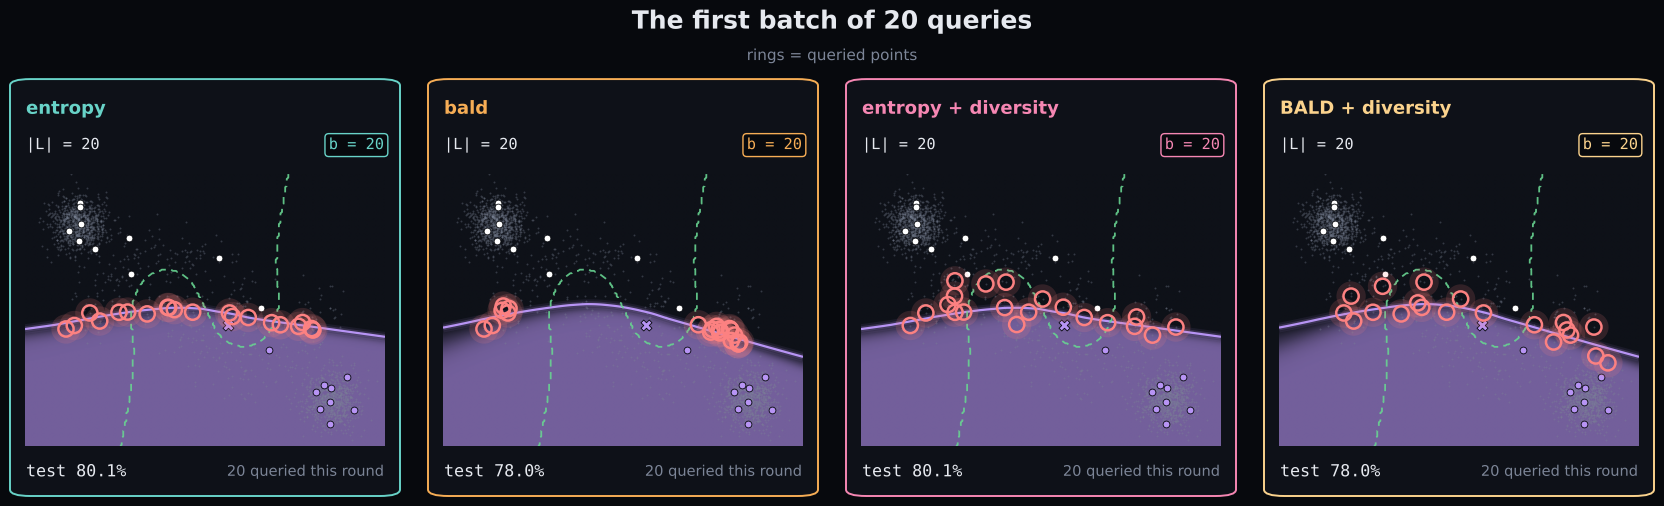

In [12]:
fig, P, _ = panel_grid(1, 4, [SCOL[k] for k in ["entropy", "bald", "entropy + diversity", "BALD + diversity"]], pw=3.9, aspect=ASP,
                       title=f"The first batch of {BATCH_B} queries", subtitle="rings = queried points")
for p_, name in zip(P, ["entropy", "bald", "entropy + diversity", "BALD + diversity"]):
    _, hist = active_learning(B_STRATS[name], REP, BATCH_B, N_SEED + BATCH_B, keep_history=True)
    L, new, m = hist[0]; plot_state(p_, m, L, new, COL["nn"], name, f"b = {BATCH_B}")
plt.show()

Top‑$b$ spends the whole batch on one or two small regions: 20 labels that carry the information of a handful. BALD top‑$b$ is the extreme case — all its queries land where the ensemble disagrees most, side by side. Clustering the candidates spreads the batch over *different* uncertain regions.

**Reading the curves.** All AL strategies end far above random sampling. With large batches, though, the two **top‑$b$** strategies are slow in the first rounds: their batches are redundant, so 20 labels are worth a handful. Adding **diversity** fixes this — **BALD + diversity** and entropy + diversity jump ahead from the very first batch.

## Summary

- On a realistic, **redundant pool**, random sampling wastes most of the budget on easy points; **entropy sampling** spends it where the boundary is and reaches the same accuracy with a fraction of the labels. How fast depends on the model: uncertainty sampling is only as good as the model's uncertainty.
- A single net's entropy mixes **aleatoric** uncertainty (ambiguous labels — querying there is wasted) and **epistemic** uncertainty (missing data — what labels fix). An **ensemble** separates them; **BALD** targets the epistemic part.
- In **deep AL** we query in batches, and **top‑$b$ selection collapses** onto near‑duplicates, wasting the first rounds. Informativeness must be combined with **diversity**.
- Link to notebook 1: **DA multiplies what we already know**; **AL goes and gets what we don't know**. They are complementary.